# Qiskit · Quantum Africa: ring-model demonstration

Classify **alfalfa, maize and wheat** from 13 satellite measurements. Follow the
organizers' flow: **load → prepare → load models → evaluate → try one field**.
The default uses verified weights; no training runs unless you enable it below.

Our **12-angle ring** is the strongest observed validation candidate (**0.8943
macro-F1**). The **8-angle ring** is a lightweight comparison (**0.8608**): about
**10× faster**, but below the SVM (**0.8797**) and our accuracy target.
Timing refers to the same cached Qiskit training method, not hardware execution.

Select **Crop challenge** or the project's **`.venv` Python 3.12** kernel, then
**Restart Kernel → Run All**. The original notebook and earlier results are preserved.

In [1]:
from pathlib import Path
import json, sys, uuid
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'challenge/data.py').exists(), 'Open the project root or notebooks/ folder'
assert sys.version_info[:2] == (3, 12) and Path(sys.prefix).resolve() == (ROOT / '.venv').resolve(), 'Select the project .venv / Crop challenge kernel'
sys.path.insert(0, str(ROOT))
from challenge.data import load_data
from challenge.metrics import score
from experiments.lightweight_ring.demo import load_models, make_model, verify_predictions

RESULTS = ROOT / 'outputs/lightweight_ring_2026-11-21'
OUT = ROOT / 'outputs/ring_demo' / uuid.uuid4().hex[:12]
OUT.mkdir(parents=True, exist_ok=False)
DEMO_SEED = 0  # Choose 0, 1 or 2; the comparison below always reports all three.
LABELS = ['alfalfa', 'maize', 'wheat']
get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
def save_show(fig, name):
    fig.savefig(OUT / (name + '.png'), dpi=150, bbox_inches='tight')
    display(fig); plt.close(fig)

tables, _, manifest, _ = load_data()
train, validation = tables['train'], tables['validation']
features = manifest['features']
print('Classes:', LABELS, '| Rows:', manifest['rows'], '| Demo seed:', DEMO_SEED)

Classes: ['alfalfa', 'maize', 'wheat'] | Rows: {'train': 914, 'validation': 150, 'test': 221} | Demo seed: 0


## 1. Prepare inputs and inspect the data

PCA combines the 13 standardized measurements into **four new numerical inputs**.
The saved preprocessing was fitted on the 914 training fields only. We reuse it
unchanged for validation. IDs and labels are not features; test data is not used.

**Read the plots:** wheat is more common in training. Each dot on the right is
a real training field; the first two PCs overlap, especially for maize and wheat.
These are feature coordinates, not geographic locations.

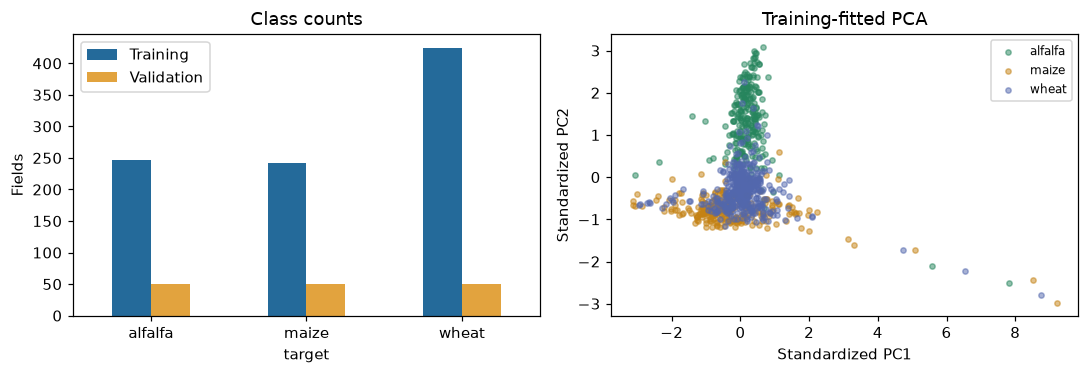

In [2]:
prep = joblib.load(RESULTS / 'preprocessing.joblib')
A = prep.transform(train[features].to_numpy())
B = prep.transform(validation[features].to_numpy())
assert A.shape == (914, 4) and B.shape == (150, 4)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
counts = pd.DataFrame({'Training': train.target.value_counts(),
                       'Validation': validation.target.value_counts()}).reindex(LABELS)
counts.plot.bar(ax=axes[0], rot=0, color=['#246a9a', '#e2a33e'])
axes[0].set(ylabel='Fields', title='Class counts')
for crop, color in zip(LABELS, ['#26855d', '#c48214', '#5267ad']):
    mask = train.target.eq(crop).to_numpy()
    axes[1].scatter(A[mask, 0], A[mask, 1], label=crop, s=12, alpha=.5, color=color)
axes[1].set(xlabel='Standardized PC1', ylabel='Standardized PC2', title='Training-fitted PCA')
axes[1].legend(fontsize=8)
fig.tight_layout(); save_show(fig, '01_data')

## 2. Understand and load the two ring models

Both use **four qubits**, the angle rule **(π/2) × (1 + tanh(x))**, and the original
readout: 16 outcomes grouped by integer modulo 3 into three crop probabilities.

The **8-angle ring** has one ring CX block between two RY banks; it uses COBYLA
with 100 calls. The **12-angle ring** has two blocks and three RY banks; it uses
L-BFGS-B, capped at 100 loss/gradient calls. Gates marked `x` load field values;
`theta` angles are learned. CX connects qubits in order **0→1→2→3→0** per block.

Below we construct the actual Qiskit circuits, then load verified weights.
**No model is trained by default.** The SVM keeps the original 13-feature settings.

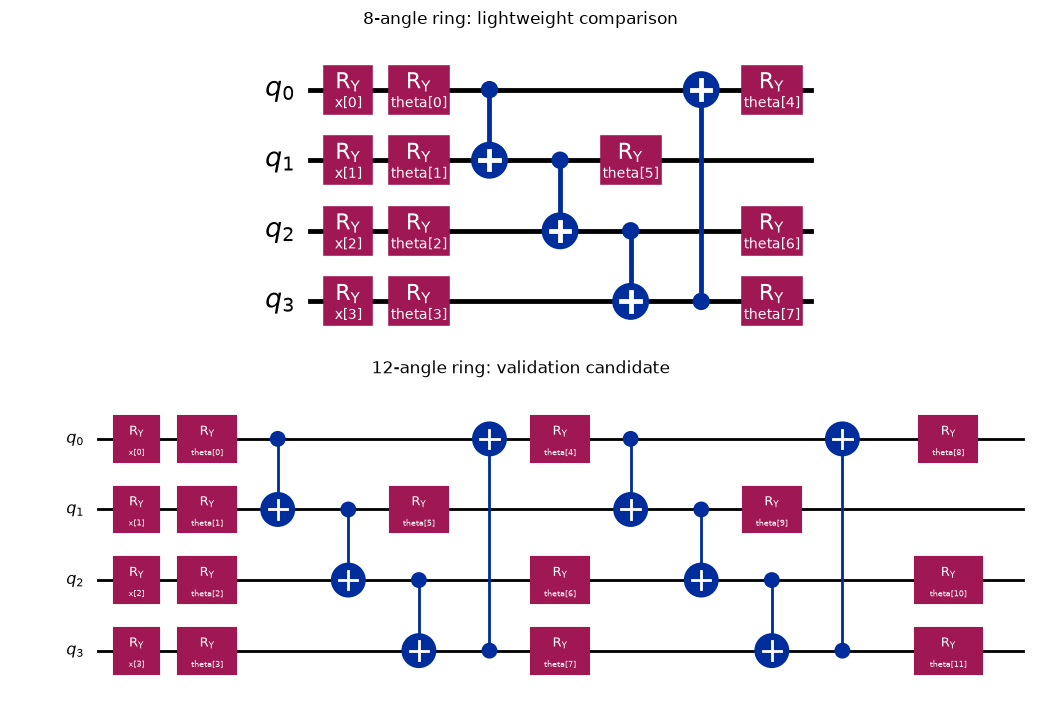

,model,qubits,angles,CX gates,depth
0,8-angle ring,4,8,4,7
1,12-angle ring,4,12,8,12


In [3]:
light_circuit = make_model(RESULTS, 'selected8')
strong_circuit = make_model(RESULTS, 'ring12')
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5))
for ax, name, model in zip(axes, ['8-angle ring: lightweight comparison', '12-angle ring: validation candidate'], [light_circuit, strong_circuit]):
    model.circuit.draw(output='mpl', ax=ax, fold=-1, style={'fontsize': 9, 'subfontsize': 6})
    ax.set_title(name, fontsize=11)
fig.tight_layout(); save_show(fig, '02_ring_circuits')
display(pd.DataFrame([{'model': name, 'qubits': m.resources()['qubits'],
                       'angles': m.resources()['trainable'], 'CX gates': m.resources()['two_qubit_gates'],
                       'depth': m.resources()['depth']}
                      for name, m in [('8-angle ring', light_circuit), ('12-angle ring', strong_circuit)]]))

In [4]:
prep, light, strong, classical = load_models(RESULTS, seed=DEMO_SEED)
# Freshly replay predictions; fail clearly if they differ from the verified files.
checks = verify_predictions(RESULTS, validation, features, prep, light, strong, classical, DEMO_SEED)
print('Saved weights loaded. Validation predictions/probabilities reproduce for both QNNs and SVM.')
display(pd.DataFrame([{'model': r['model'], 'seed': r['seed'], 'macro-F1': r['metrics']['macro_f1'],
                       'accuracy': r['metrics']['accuracy']} for r in checks]))

Saved weights loaded. Validation predictions/probabilities reproduce for both QNNs and SVM.


,model,seed,macro-F1,accuracy
0,selected8,0,0.868555,0.866667
1,ring12,0,0.894346,0.893333
2,svm,0,0.879740,0.880000


## 3. Read the verified comparison

These are saved measurements from fresh same-machine runs on **914 training /
150 validation fields, seeds 0/1/2**. They do not retrain when plotted.
**Macro-F1** balances precision and recall equally across crops; **accuracy**
counts correct fields. **Precision** asks how often a crop prediction is right;
**recall** asks how many real fields of that crop we find.

All reported QNN training uses the same **cached Qiskit evaluator**; inference
uses standard **SamplerQNN**. The SVM is classical and uses all 13 features.
These are local simulator times, not hardware performance or quantum advantage.

**Read the figures:** loss is lower-is-better on training, not validation.
Confusion rows are actual crops and columns predictions; the diagonal shows recall.
Performance dots show seeds, not independent datasets or confidence intervals.

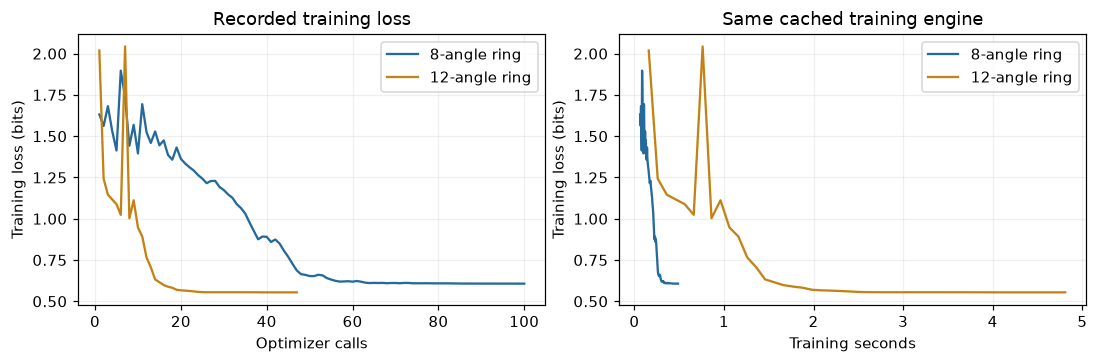

In [5]:
names = {'ring12': '12-angle ring', 'selected8': '8-angle ring', 'svm': 'SVM'}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for model, color in [('selected8', '#246a9a'), ('ring12', '#c48214')]:
    h = pd.read_json(RESULTS / 'full' / f'{model}_seed_{DEMO_SEED}_history.json')
    axes[0].plot(h.evaluation, h.objective_bits, label=names[model], color=color)
    axes[1].plot(h.seconds, h.objective_bits, label=names[model], color=color)
for ax in axes:
    ax.set_ylabel('Training loss (bits)'); ax.legend(); ax.grid(alpha=.2)
axes[0].set(xlabel='Optimizer calls', title='Recorded training loss')
axes[1].set(xlabel='Training seconds', title='Same cached training engine')
fig.tight_layout(); save_show(fig, '03_training')
# One chosen COBYLA call uses 1 probability pass; a 12-angle gradient call uses 25.

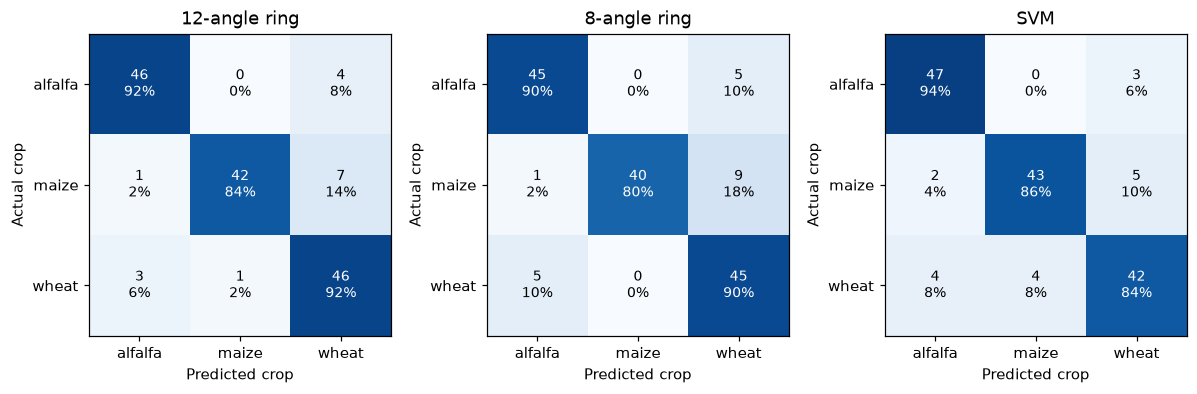

In [6]:
runs = json.loads((RESULTS / 'runs.json').read_text())
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, name in zip(axes, names):
    r = next(r for r in runs if r['model'] == name and r['seed'] == DEMO_SEED)
    cm = np.asarray(r['metrics']['confusion']); fraction = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(fraction, vmin=0, vmax=1, cmap='Blues')
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{cm[i,j]}\n{fraction[i,j]:.0%}', ha='center', va='center',
                    color='white' if fraction[i,j] > .55 else 'black', fontsize=9)
    ax.set(xticks=range(3), yticks=range(3), xticklabels=LABELS, yticklabels=LABELS,
           xlabel='Predicted crop', ylabel='Actual crop', title=names[name])
fig.tight_layout(); save_show(fig, '04_confusion')

,model,seed,macro_f1,accuracy,prep_s,train_s,infer_s,total_s
0,selected8,0,0.8686,0.8667,0.0011,0.4871,0.0851,0.5732
1,selected8,1,0.8686,0.8667,0.0011,0.4850,0.0789,0.5650
2,selected8,2,0.8452,0.8467,0.0011,0.4852,0.0860,0.5723
3,ring12,0,0.8943,0.8933,0.0011,4.8095,0.0950,4.9055
4,ring12,1,0.8943,0.8933,0.0012,6.9003,0.0907,6.9923
5,ring12,2,0.8943,0.8933,0.0013,5.6380,0.0949,5.7342
9,svm,0,0.8797,0.8800,0.0003,0.0048,0.0009,0.0060
10,svm,1,0.8797,0.8800,0.0003,0.0048,0.0009,0.0060
11,svm,2,0.8797,0.8800,0.0003,0.0047,0.0009,0.0059


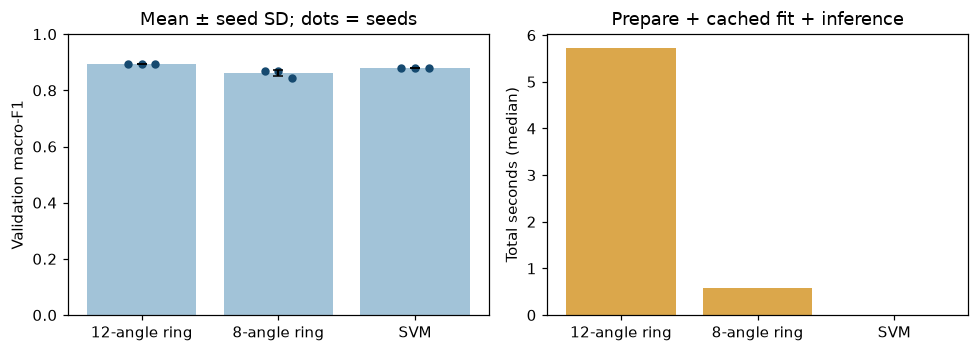

,model,crop,precision,recall
0,12-angle ring,alfalfa,92.0%,92.0%
1,12-angle ring,maize,97.7%,84.0%
2,12-angle ring,wheat,80.7%,92.0%
3,8-angle ring,alfalfa,88.2%,90.0%
4,8-angle ring,maize,93.9%,83.3%
5,8-angle ring,wheat,78.9%,84.7%
6,SVM,alfalfa,88.7%,94.0%
7,SVM,maize,91.5%,86.0%
8,SVM,wheat,84.0%,84.0%


In [7]:
metrics = pd.read_csv(RESULTS / 'per_seed_metrics.csv')
metrics = metrics[metrics.model.isin(names)].copy()
display(metrics[['model', 'seed', 'macro_f1', 'accuracy', 'preprocessing_seconds',
                 'fit_seconds', 'inference_seconds', 'total_seconds']].rename(columns={
                 'preprocessing_seconds': 'prep_s', 'fit_seconds': 'train_s',
                 'inference_seconds': 'infer_s', 'total_seconds': 'total_s'}).round(4))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for i, name in enumerate(names):
    g = metrics[metrics.model == name]
    axes[0].bar(i, g.macro_f1.mean(), yerr=g.macro_f1.std(ddof=0), color='#a2c3d8', capsize=3)
    axes[0].scatter(i + np.linspace(-.1, .1, 3), g.macro_f1, color='#164a70', s=20)
    axes[1].bar(i, g.total_seconds.median(), color='#dba74b')
for ax in axes: ax.set_xticks(range(3), list(names.values()))
axes[0].set(ylabel='Validation macro-F1', ylim=(0,1), title='Mean ± seed SD; dots = seeds')
axes[1].set(ylabel='Total seconds (median)', title='Prepare + cached fit + inference')
fig.tight_layout(); save_show(fig, '05_accuracy_runtime')
crop_rows = [{'model': names[m], 'crop': c, 'precision': metrics.loc[metrics.model == m, f'precision_{c}'].mean(),
              'recall': metrics.loc[metrics.model == m, f'recall_{c}'].mean()} for m in names for c in LABELS]
display(pd.DataFrame(crop_rows).style.format({'precision': '{:.1%}', 'recall': '{:.1%}'}))

## 4. Optional retraining — off by default

Leave `RETRAIN=False` for the demonstration. Enable it only if you want to repeat
one established fit on all 914 training fields. Select `ring12` or `selected8`;
weights are saved to this session's new output folder. The loaded demonstration
models and original experiment files are unchanged.

In [8]:
RETRAIN = False
MODEL_TO_RETRAIN = 'ring12'  # Or 'selected8'; both keep their verified configuration.
if RETRAIN:
    fresh = make_model(RESULTS, MODEL_TO_RETRAIN).fit(A, train.target.to_numpy(), seed=DEMO_SEED)
    print('FRESH retraining result:', score(validation.target, fresh.predict(B), LABELS))
    np.savez_compressed(OUT / f'retrained_{MODEL_TO_RETRAIN}.npz', weights=fresh.model.weights)
else:
    print('Retraining skipped. The demo uses verified saved weights.')

Retraining skipped. The demo uses verified saved weights.


In [9]:
selection = json.loads((RESULTS / 'training_only_selection.json').read_text())
chosen = next(r for r in selection['candidates'] if r['name'] == selection['selected_configuration'])
reference_cv = next(r for r in selection['candidates'] if r['name'] == 'ring12')
display(pd.DataFrame([{'model': name, 'training-only CV macro-F1': r['mean_oof_macro_f1'],
                       'median three-fold seconds': r['median_three_fold_total_seconds']}
                      for name, r in [('8-angle selected', chosen), ('12-angle ring', reference_cv)]]))
print('Eight-angle choice from training only:', chosen['optimizer'], '| maximum calls:', chosen['max_evals'])

,model,training-only CV macro-F1,median three-fold seconds
0,8-angle selected,0.843000,1.459367
1,12-angle ring,0.852669,12.799991


Eight-angle choice from training only: COBYLA | maximum calls: 100


**Conclusion:** the 12-angle ring remains our strongest observed validation
candidate. The 8-angle ring is about 10× faster here, but its mean F1 **0.8608**
misses the **0.88–0.89** target and is less stable across seeds. It is a useful
lightweight comparison, not a forced improvement. The SVM remains competitive.

The speed study chose the 8-angle budget from **training-only CV**, before
validation. The earlier broader topology CV selected **full connectivity**;
the ring model's higher **observed validation** score is separate evidence.
No best validation seed was selected. Detailed budgets and logs stay in
`experiments/lightweight_ring/` and its separate results folder.

## 5. Try one actual validation field

Change `FIELD_INDEX` (0–149) and rerun the cell. It predicts a real held-out field
with both frozen ring models and the SVM. The label is shown for checking, never
used to change the weights. The probability table belongs to the two QNNs;
the original SVM does not provide calibrated crop probabilities.

In [10]:
FIELD_INDEX = 0
assert 0 <= FIELD_INDEX < len(validation), 'Choose a field index from 0 to 149'
field = validation.iloc[FIELD_INDEX]
p8 = light.predict_proba(B[[FIELD_INDEX]])[0]
p12 = strong.predict_proba(B[[FIELD_INDEX]])[0]
svm_label = classical.predict(validation.iloc[[FIELD_INDEX]][features].to_numpy())[0]
print('Field:', field.sample_id, '| actual crop:', field.target, '| NDVI:', round(field.NDVI, 4))
demo_predictions = [LABELS[p12.argmax()], LABELS[p8.argmax()], svm_label]
display(pd.DataFrame({'model': ['12-angle ring', '8-angle ring', 'SVM'],
                      'prediction': demo_predictions, 'actual crop': [field.target] * 3,
                      'correct': np.asarray(demo_predictions) == field.target}))
display(pd.DataFrame({'crop': LABELS, '12-angle probability': p12, '8-angle probability': p8}).round(4))

Field: r2_4769de2441c6188e | actual crop: wheat | NDVI: 0.2668


,model,prediction,actual crop,correct
0,12-angle ring,wheat,wheat,True
1,8-angle ring,wheat,wheat,True
2,SVM,wheat,wheat,True


,crop,12-angle probability,8-angle probability
0,alfalfa,0.0171,0.0366
1,maize,0.0936,0.0844
2,wheat,0.8894,0.8790


## Files and running the demo

The notebook uses existing model code and the completed benchmark; it does not
start an architecture search. See `experiments/lightweight_ring/README.md` for
the full protocol, counters and standard-versus-cached evaluator measurements.
Standard optimizer training time was not measured; reported fits are cached.

In VS Code: select **Crop challenge / `.venv` Python 3.12**, then **Restart Kernel →
Run All**. Change only `FIELD_INDEX` to explore another field. To change the saved
seed, edit `DEMO_SEED` near the top and run all again. Optional retraining stays off.